# Grid and Randomized Search

This notebook tunes a pipeline with `GridSearchCV` and `RandomizedSearchCV`, inspects `cv_results_`, visualises the grid, and demonstrates the optimistic bias of non-nested selection.

## Import Required Libraries

Import the dataset, pipeline building blocks and search tools.

In [1]:
# Import the required libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import (
    GridSearchCV, RandomizedSearchCV, cross_val_score, KFold
)
from scipy.stats import loguniform

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Build the Pipeline

Chain a standard scaler with a support vector classifier so that scaling is refit inside every cross-validation fold.

In [2]:
# Build a scaling + SVM pipeline.
data = load_breast_cancer()
X, y = data.data, data.target
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf")),
])

## Grid Search over Two Hyperparameters

Search a grid of the SVM regularisation `C` and kernel width `gamma`.

In [3]:
# Run an exhaustive grid search over C and gamma.
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [1e-3, 1e-2, 1e-1, 1],
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy")
grid.fit(X, y)
print(f"Best params: {grid.best_params_}.")
print(f"Best CV score: {grid.best_score_:.4f}.")
print(f"Evaluations: {len(grid.cv_results_['params'])} "
      f"x 5 folds.")

Best params: {'svc__C': 10, 'svc__gamma': 0.01}.
Best CV score: 0.9789.
Evaluations: 16 x 5 folds.


## Inspect cv_results_ as a DataFrame

The `cv_results_` dictionary converts to a DataFrame for sorting and inspection.

In [4]:
# Inspect the top grid-search results.
results = pd.DataFrame(grid.cv_results_)
cols = ["param_svc__C", "param_svc__gamma",
        "mean_test_score", "std_test_score", "rank_test_score"]
top = results[cols].sort_values("rank_test_score").head()
print(top.to_string(index=False))

 param_svc__C  param_svc__gamma  mean_test_score  std_test_score  rank_test_score
         10.0             0.010         0.978932        0.006990                1
         10.0             0.001         0.970144        0.008903                2
        100.0             0.001         0.970144        0.006963                2
          1.0             0.010         0.968390        0.008897                4
        100.0             0.010         0.968374        0.008919                5


## Heatmap of the Grid

Reshape the mean scores into a C-by-gamma grid and display it as a heatmap.

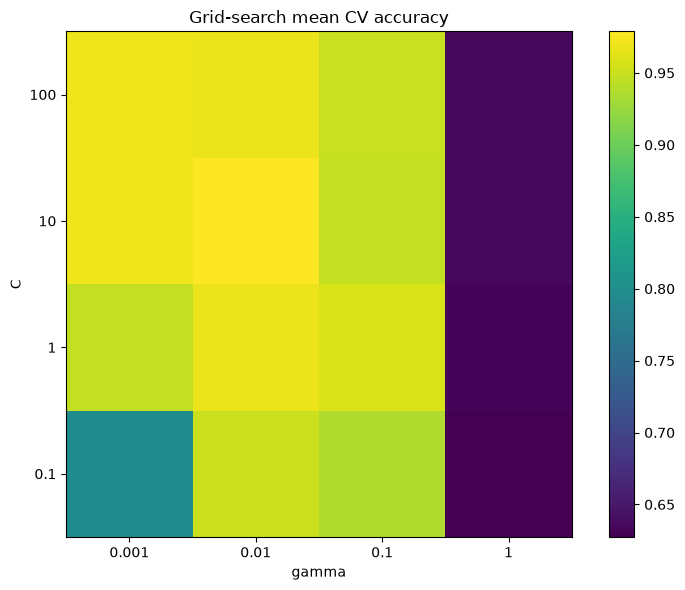

In [5]:
# Plot the mean CV score over the two hyperparameters.
scores = results["mean_test_score"].to_numpy().reshape(4, 4)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(scores, cmap="viridis", origin="lower")
ax.set_xticks(range(4))
ax.set_xticklabels(param_grid["svc__gamma"])
ax.set_yticks(range(4))
ax.set_yticklabels(param_grid["svc__C"])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
ax.set_title("Grid-search mean CV accuracy")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Randomized Search

`RandomizedSearchCV` samples a fixed number of configurations from continuous distributions, often reaching a good score with fewer evaluations.

In [6]:
# Run a randomized search with sampled distributions.
param_dist = {
    "svc__C": loguniform(1e-1, 1e2),
    "svc__gamma": loguniform(1e-3, 1e0),
}
rand = RandomizedSearchCV(
    pipe, param_dist, n_iter=10, cv=5,
    scoring="accuracy", random_state=42
)
rand.fit(X, y)
print(f"Best params: {rand.best_params_}.")
print(f"Best CV score: {rand.best_score_:.4f}.")
print(f"Evaluations: {rand.n_iter} x 5 folds.")

Best params: {'svc__C': np.float64(31.428808908401084), 'svc__gamma': np.float64(0.004335281794951566)}.
Best CV score: 0.9754.
Evaluations: 10 x 5 folds.


## Evaluations vs Best Score

Compare the budget and the best score of the two strategies.

In [7]:
# Compare evaluations and best score of both searches.
print(f"Grid:   {len(grid.cv_results_['params'])} configs, "
      f"best {grid.best_score_:.4f}.")
print(f"Random: {rand.n_iter} configs, "
      f"best {rand.best_score_:.4f}.")

Grid:   16 configs, best 0.9789.
Random: 10 configs, best 0.9754.


## Nested Cross-Validation

A non-nested score reuses the same data for tuning and evaluation and is optimistically biased; nested CV wraps the search in an outer loop for an honest estimate.

In [8]:
# Compare non-nested and nested cross-validation scores.
inner = KFold(n_splits=3, shuffle=True, random_state=42)
outer = KFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(pipe, param_grid, cv=inner,
                      scoring="accuracy")
search.fit(X, y)
non_nested = search.best_score_

nested = cross_val_score(search, X, y, cv=outer).mean()
print(f"Non-nested score: {non_nested:.4f}.")
print(f"Nested score:     {nested:.4f}.")
print(f"Optimism: {non_nested - nested:.4f}.")

Non-nested score: 0.9771.
Nested score:     0.9701.
Optimism: 0.0070.


## Summary

- **GridSearchCV**: exhaustively evaluates every combination; cost grows quickly with the grid size.
- **RandomizedSearchCV**: samples configurations, often matching the grid with a fraction of the evaluations.
- **Pipelines**: keep preprocessing inside the CV loop so scaling is refit on each training fold, avoiding leakage.
- **Nested CV**: separates tuning from evaluation and removes the optimistic bias of a non-nested selection score.